# 05: Feature selection

This notebook tests whether selecting features improves the logistic-regression baseline. It compares the full feature set with mutual-information filters and L1-based selection.

**Leakage safeguards:** preprocessing and feature selection are fitted inside each cross-validation fold. Methods are compared using the same five stratified folds and PR-AUC as the baseline. The test set is reserved for one final comparison: the CV-selected method against the full-feature baseline.

## 1. Load the training data and set up the protocol

The split is already fixed in `dataset/train.csv` and `dataset/test.csv`. During selection, only the training portion is used. Do not inspect test scores to choose a method.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_selection import SelectFromModel, SelectPercentile, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from common import RESULTS, FIGURES, cv_folds, make_preprocessor, random_split, set_seed, xy
from evaluation import SCORING, bootstrap_ci, paired_bootstrap_diff, ranking_metrics

set_seed()
RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

train, test = random_split()
X_train, y_train = xy(train)
print(f"Training data: {X_train.shape[0]:,} rows, {X_train.shape[1]} original features")
print(f"Positive class share: {y_train.mean():.3%}")
cv = cv_folds()

Training data: 32,940 rows, 20 original features
Positive class share: 11.266%


## 2. Define selection methods

All selectors operate on the transformed features inside the pipeline. Mutual information ranks each transformed column; L1 logistic regression selects columns using coefficient magnitude. These methods are exploratory and may select individual encoded categories rather than whole original variables.

In [2]:
def mi_score(X, y):
    """Use a fixed seed so mutual-information scores are reproducible."""
    return mutual_info_classif(X, y, random_state=42)


def make_selector(method):
    if method == "all_features":
        return None
    if method == "mi_50":
        return SelectPercentile(score_func=mi_score, percentile=50)
    if method == "mi_75":
        return SelectPercentile(score_func=mi_score, percentile=75)
    if method == "l1_median":
        selector_model = LogisticRegression(
            l1_ratio=1.0, C=0.1, solver="liblinear", max_iter=5000, random_state=42
        )
        return SelectFromModel(selector_model, threshold="median")
    if method == "l1_strict":
        selector_model = LogisticRegression(
            l1_ratio=1.0, C=0.1, solver="liblinear", max_iter=5000, random_state=42
        )
        return SelectFromModel(selector_model, threshold="1.25*mean")
    raise ValueError(f"Unknown feature-selection method: {method}")


def make_pipeline(method="all_features"):
    steps = [("prep", make_preprocessor())]
    selector = make_selector(method)
    if selector is not None:
        steps.append(("select", selector))
    steps.append((
        "model",
        LogisticRegression(C=0.1, class_weight=None, max_iter=5000, random_state=42),
    ))
    return Pipeline(steps)


def model_score(fitted_pipeline, X):
    if hasattr(fitted_pipeline, "predict_proba"):
        return fitted_pipeline.predict_proba(X)[:, 1]
    return fitted_pipeline.decision_function(X)


methods = ["all_features", "mi_50", "mi_75", "l1_median", "l1_strict"]

## 3. Compare methods with five-fold cross-validation

The same folds and PR-AUC scoring are used for each method. The train score is included as a diagnostic for overfitting; selection is based on mean validation PR-AUC.

In [3]:
cv_rows = []
for method in methods:
    scores = cross_validate(
        make_pipeline(method),
        X_train,
        y_train,
        cv=cv,
        scoring=SCORING,
        return_train_score=True,
        n_jobs=1,
    )
    cv_rows.append({
        "method": method,
        "cv_pr_auc_mean": scores["test_pr_auc"].mean(),
        "cv_pr_auc_std": scores["test_pr_auc"].std(),
        "cv_roc_auc_mean": scores["test_roc_auc"].mean(),
        "cv_roc_auc_std": scores["test_roc_auc"].std(),
        "train_pr_auc_mean": scores["train_pr_auc"].mean(),
        "fit_time_s": scores["fit_time"].mean(),
    })

cv_results = pd.DataFrame(cv_rows).sort_values("cv_pr_auc_mean", ascending=False).reset_index(drop=True)
cv_results.round(4)

,method,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean,cv_roc_auc_std,train_pr_auc_mean,fit_time_s
0,l1_median,0.4489,0.0056,0.7889,0.0108,0.4552,0.5490
1,all_features,0.4484,0.0056,0.7886,0.0108,0.4558,0.2231
2,mi_75,0.4484,0.0053,0.7868,0.0102,0.4538,3.5894
3,mi_50,0.4447,0.0039,0.7869,0.0112,0.4496,3.5658
4,l1_strict,0.4412,0.0068,0.7879,0.0093,0.4431,0.5319


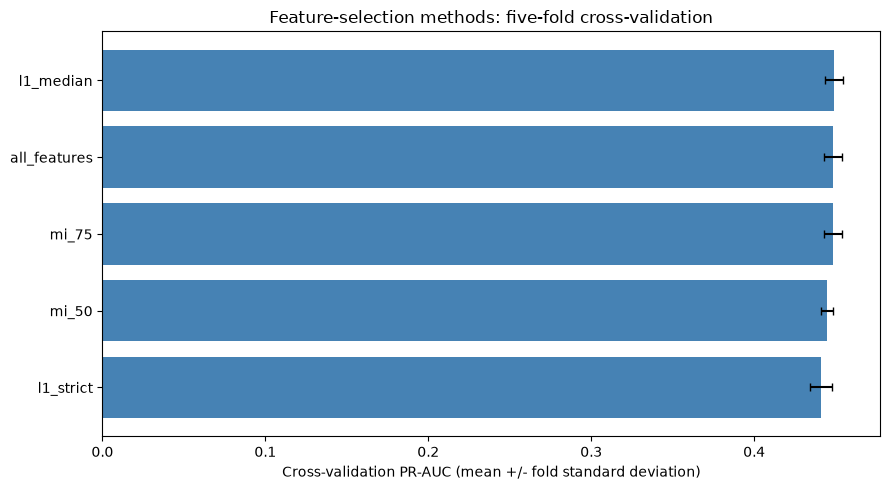

Method selected using CV only: l1_median


In [4]:
cv_results.to_csv(RESULTS / "feature_selection_cv.csv", index=False)

plot_data = cv_results.sort_values("cv_pr_auc_mean")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_data["method"], plot_data["cv_pr_auc_mean"],
        xerr=plot_data["cv_pr_auc_std"], color="steelblue", capsize=3)
ax.set_xlabel("Cross-validation PR-AUC (mean +/- fold standard deviation)")
ax.set_title("Feature-selection methods: five-fold cross-validation")
fig.tight_layout()
fig.savefig(FIGURES / "feature_selection_cv.png", dpi=150)
plt.show()

best_method = cv_results.loc[0, "method"]
print(f"Method selected using CV only: {best_method}")

## 4. One final test-set comparison

After selecting a method using cross-validation, fit the full-feature baseline and the selected method on all training rows. Evaluate only these on the held-out test set; do not use these results to choose a different method.

In [5]:
X_test, y_test = xy(test)
baseline = make_pipeline("all_features").fit(X_train, y_train)
baseline_test_score = model_score(baseline, X_test)

if best_method == "all_features":
    selected_pipeline = baseline
    selected_test_score = baseline_test_score
else:
    selected_pipeline = make_pipeline(best_method).fit(X_train, y_train)
    selected_test_score = model_score(selected_pipeline, X_test)

test_rows = []
for method, scores in [("all_features", baseline_test_score)]:
    metrics = ranking_metrics(y_test, scores)
    ci_low, ci_high = bootstrap_ci(y_test, scores, average_precision_score)
    test_rows.append({"method": method, **metrics,
                      "pr_auc_ci_low": ci_low, "pr_auc_ci_high": ci_high})

if best_method != "all_features":
    metrics = ranking_metrics(y_test, selected_test_score)
    ci_low, ci_high = bootstrap_ci(y_test, selected_test_score, average_precision_score)
    test_rows.append({"method": best_method, **metrics,
                      "pr_auc_ci_low": ci_low, "pr_auc_ci_high": ci_high})

test_results = pd.DataFrame(test_rows)
test_results.to_csv(RESULTS / "feature_selection_test.csv", index=False)
test_results.round(4)

,method,pr_auc,roc_auc,recall_top20,pr_auc_ci_low,pr_auc_ci_high
0,all_features,0.4540,0.8004,0.6401,0.4175,0.4882
1,l1_median,0.4552,0.8010,0.6455,0.4189,0.4897


In [6]:
paired = paired_bootstrap_diff(
    y_test,
    selected_test_score,
    baseline_test_score,
    average_precision_score,
)
pd.DataFrame([{"selected_method": best_method, **paired}]).to_csv(
    RESULTS / "feature_selection_paired.csv", index=False
)
print("Paired test PR-AUC difference (selected minus baseline):")
print(f"{paired['diff']:.4f}; 95% bootstrap CI [{paired['ci_low']:.4f}, {paired['ci_high']:.4f}]")
print("If the interval includes zero, the test does not show a clear improvement.")

Paired test PR-AUC difference (selected minus baseline):
0.0012; 95% bootstrap CI [-0.0004, 0.0029]
If the interval includes zero, the test does not show a clear improvement.


## 5. Inspect the selected features and save the outputs

The final selector is refitted on training data only. For one-hot encoded variables, each listed item is a transformed category column, not necessarily a whole original feature.

In [7]:
transformed_names = selected_pipeline.named_steps["prep"].get_feature_names_out()
if best_method == "all_features":
    selected_names = transformed_names
else:
    selected_names = transformed_names[selected_pipeline.named_steps["select"].get_support()]

feature_list = pd.DataFrame({"selected_feature": selected_names})
feature_list.to_csv(RESULTS / "feature_selection_names.csv", index=False)
print(f"Selected {len(selected_names)} transformed columns using {best_method}:")
feature_list

Selected 32 transformed columns using l1_median:


,selected_feature
0,job_admin.
1,job_blue-collar
2,job_retired
3,job_services
4,job_student
5,marital_divorced
6,marital_married
7,education_basic.9y
8,education_high.school
9,education_university.degree


## Interpretation

Compare the selected method's validation PR-AUC with the all-feature baseline and consider the fold variability. On the test set, report the paired bootstrap interval rather than claiming improvement from a small point-estimate difference. Feature selection is useful only if it improves predictive performance or gives a meaningful reduction in complexity without harming the ranking objective.